In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

**Мини-вывод:** Подключил библиотеки

In [2]:
# Загрузка датасета
df = pd.read_csv("Train (1).csv")

X = df[["Discount_offered", "Weight_in_gms"]].values
y = df["Reached.on.Time_Y.N"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Данные успешно отмасштабированы. Первые 3 заказа (Скидка, Вес):")
print(np.round(X_train_scaled[:3], 2))

Данные успешно отмасштабированы. Первые 3 заказа (Скидка, Вес):
[[ 1.21 -1.  ]
 [-0.76 -1.47]
 [-0.52  0.87]]


**Мини-вывод:** Взяли два признака - скидку (`Discount_offered`) и вес (`Weight_in_gms`), и привели их к одному масштабу через `StandardScaler`

In [3]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_linear.fit(X_train_scaled, y_train)

y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 66.9%


**Мини-вывод:** Обычный линейный SVM показал точность `66.9%`.

In [4]:
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
n_sv = len(svm_rbf.support_vectors_)
sv_share = n_sv / len(X_train_scaled) * 100
print(f"Точность RBF SVM: {acc_rbf*100:.1f}%")

Точность RBF SVM: 67.9%


**Мини-вывод:** С ядром RBF точность выросла до `67.9%` - кривая граница сработала чуть лучше прямой. Опорными стали `68.7%` заказов.

In [5]:
svm_c_small = SVC(kernel="linear", C=0.01, random_state=42)
svm_c_small.fit(X_train_scaled, y_train)
acc_c_small = accuracy_score(y_test, svm_c_small.predict(X_test_scaled))

svm_c_big = SVC(kernel="linear", C=1000, random_state=42)
svm_c_big.fit(X_train_scaled, y_train)
acc_c_big = accuracy_score(y_test, svm_c_big.predict(X_test_scaled))

print(f"Линейный SVM (C=0.01): точность {acc_c_small*100:.1f}%, опорных векторов - {len(svm_c_small.support_vectors_)}")
print(f"Линейный SVM (C=1000): точность {acc_c_big*100:.1f}%, опорных векторов - {len(svm_c_big.support_vectors_)}")

Линейный SVM (C=0.01): точность 67.1%, опорных векторов - 6082
Линейный SVM (C=1000): точность 66.9%, опорных векторов - 5964


**Мини-вывод:** При мягком зазоре `C=0.01` точность даже чуть выше `67.1%` против `66.9%` при `C=1000`, а опорных векторов больше `6082` против `5964`. Огромный штраф `C=1000` на этих шумных данных не помогает

## 4. Визуализация разделяющей гиперплоскости

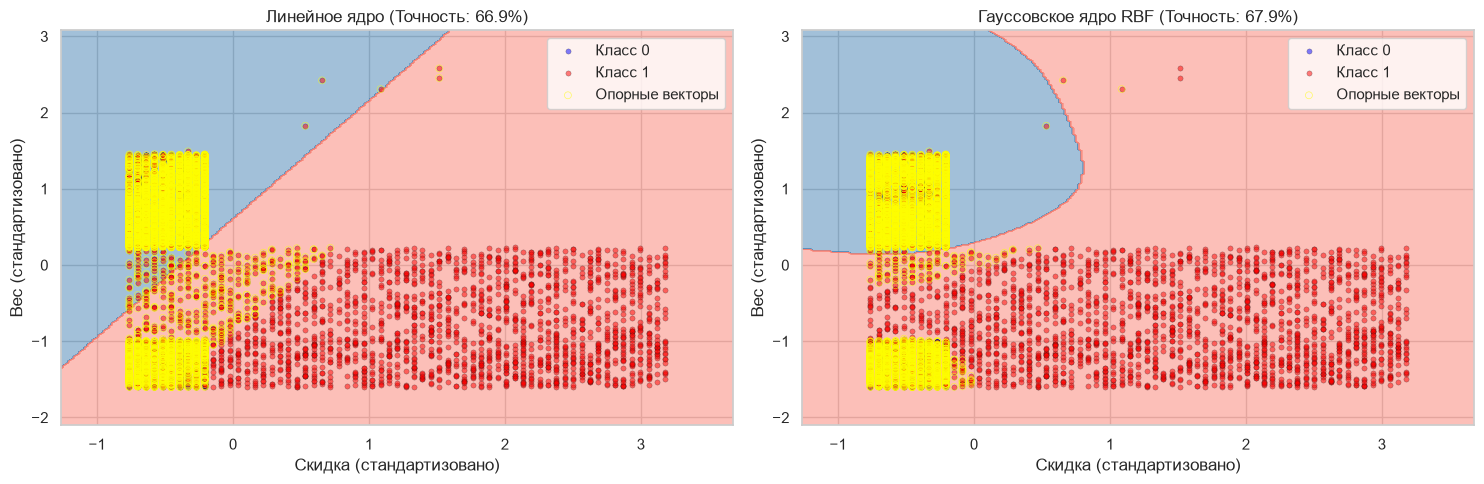

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train_scaled, y_train

    X1, X2 = np.meshgrid(
        np.arange(start=X_set[:, 0].min() - 0.5, stop=X_set[:, 0].max() + 0.5, step=0.02),
        np.arange(start=X_set[:, 1].min() - 0.5, stop=X_set[:, 1].max() + 0.5, step=0.02),
    )

    ax.contourf(
        X1, X2, model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "salmon"))
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            s=14,
            alpha=0.5,
            linewidth=0.3,
            edgecolors="k",
            label=f"Класс {j}"
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=25,
        linewidth=0.5,
        alpha=0.6,
        facecolors="none",
        edgecolors="yellow",
        label="Опорные векторы"
    )
    ax.set_title(title)
    ax.set_xlabel("Скидка (стандартизовано)")
    ax.set_ylabel("Вес (стандартизовано)")
    ax.legend()

plot_decision_boundary(svm_linear, axes[0], f"Линейное ядро (Точность: {acc_lin*100:.1f}%)")
plot_decision_boundary(svm_rbf, axes[1], f"Гауссовское ядро RBF (Точность: {acc_rbf*100:.1f}%)")

plt.tight_layout()
plt.show()

**Мини-вывод:** На графиках видно, что при маленьких скидках (левая часть) точки сильно перемешаны, поэтому там почти всё обведено жёлтым. А справа при больших скидках идут почти одни красные точки (опоздания) без жёлтой обводки. Ядро RBF справа аккуратно обводит синюю область сверху слева, поэтому даёт чуть выше точность (`67.9%`).

In [8]:
svm_linear = SVC(
    kernel="linear",
    C=0.1,
    gamma="scale",
    random_state=42
)
svm_linear.fit(X_train_scaled, y_train)

y_pred_lin = svm_linear.predict(X_test_scaled)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 67.0%


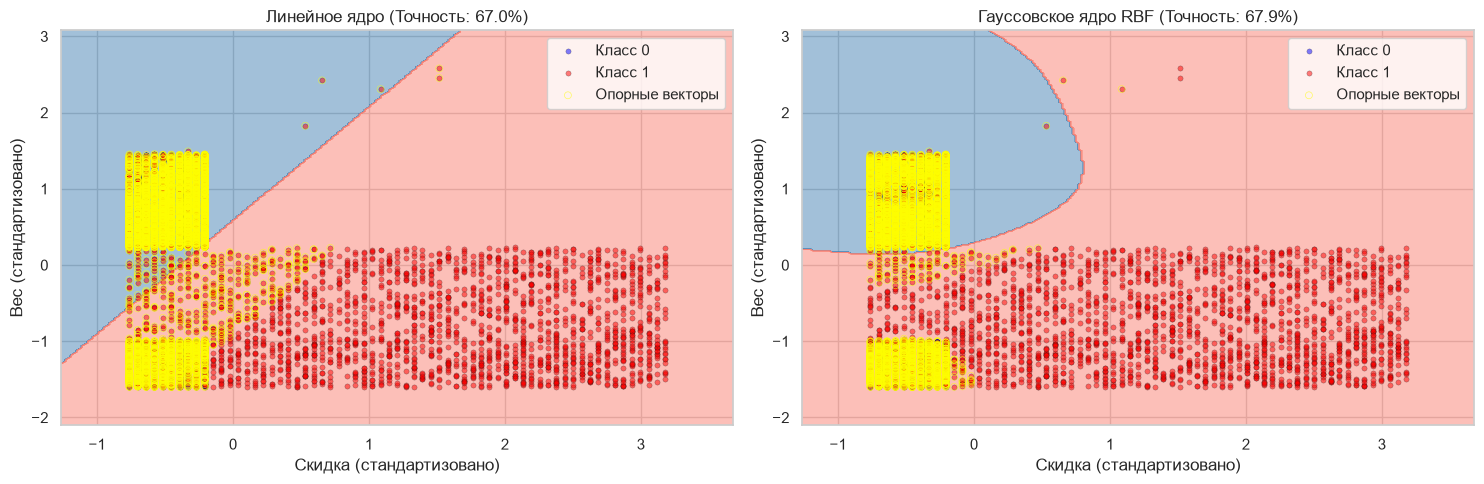

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def plot_decision_boundary(model, ax, title):
    X_set, y_set = X_train_scaled, y_train

    X1, X2 = np.meshgrid(
        np.arange(start=X_set[:, 0].min() - 0.5, stop=X_set[:, 0].max() + 0.5, step=0.02),
        np.arange(start=X_set[:, 1].min() - 0.5, stop=X_set[:, 1].max() + 0.5, step=0.02),
    )

    ax.contourf(
        X1, X2, model.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
        alpha=0.5,
        cmap=ListedColormap(("steelblue", "salmon"))
    )

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            s=14,
            alpha=0.5,
            linewidth=0.3,
            edgecolors="k",
            label=f"Класс {j}"
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=25,
        linewidth=0.5,
        alpha=0.6,
        facecolors="none",
        edgecolors="yellow",
        label="Опорные векторы"
    )
    ax.set_title(title)
    ax.set_xlabel("Скидка (стандартизовано)")
    ax.set_ylabel("Вес (стандартизовано)")
    ax.legend()

plot_decision_boundary(svm_linear, axes[0], f"Линейное ядро (Точность: {acc_lin*100:.1f}%)")
plot_decision_boundary(svm_rbf, axes[1], f"Гауссовское ядро RBF (Точность: {acc_rbf*100:.1f}%)")

plt.tight_layout()
plt.show()

Изменений нет, поэтому можно сделать вывод, что С не влияет на результат

### вывод
* **Linear vs RBF:** ядро RBF сработало чуть лучше линейного (`67.9%` против `66.9%`), потому что граница между классами нелинейна.
* **Доля опорных векторов:** `68.7%` заказов  попали в опорные - при маленьких скидках классы сильно пересекаются, а вот примерно 31.3% заказов модель уверенно выносит за границу и не опирается на них.